In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans

--- Generating Dataset Pairplot ---


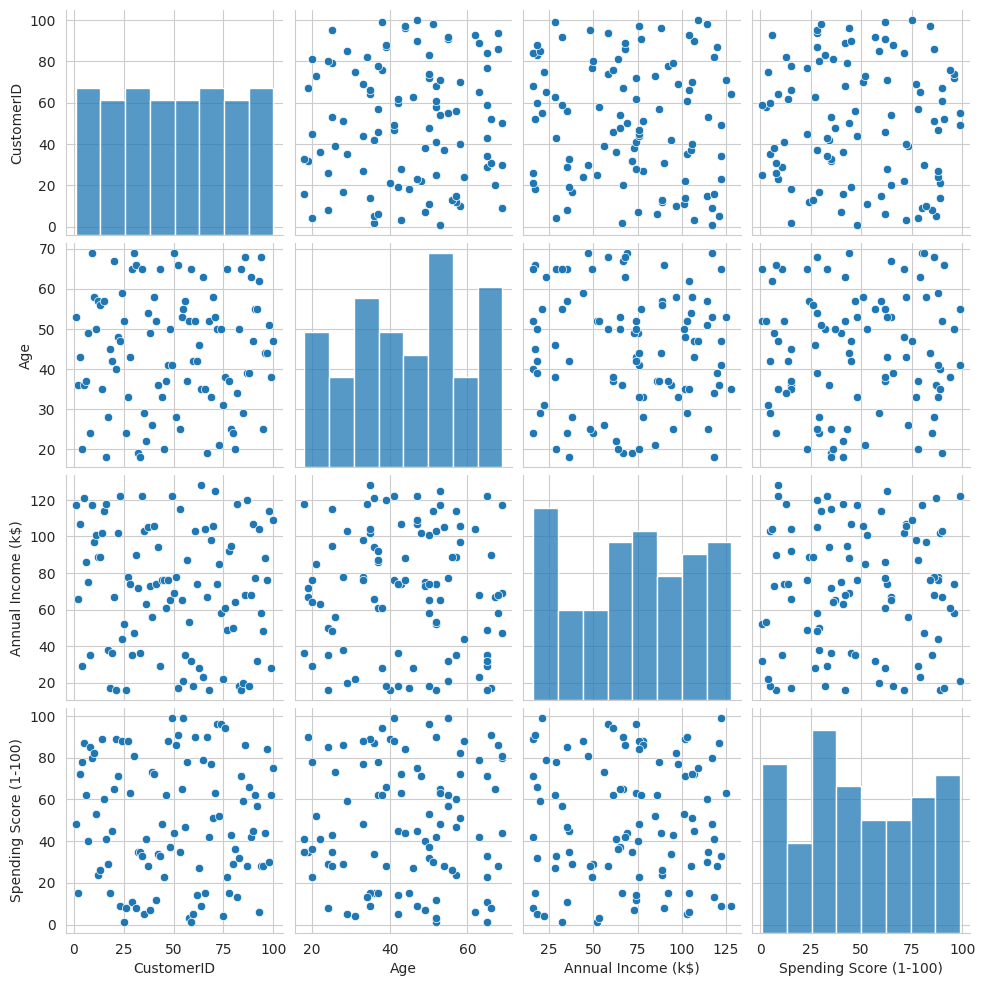

In [7]:
np.random.seed(42)

mock_income = np.random.randint(15, 130, size=100)
mock_spending = np.random.randint(1, 100, size=100)

df = pd.DataFrame({
    "CustomerID": np.arange(1, 101),
    "Gender": np.random.choice(["Male", "Female"], size=100),
    "Age": np.random.randint(18, 70, size=100),
    "Annual Income (k$)": mock_income,
    "Spending Score (1-100)": mock_spending
})

print("--- Generating Dataset Pairplot ---")
sns.pairplot(df)
plt.show()


In [8]:
features = df.iloc[:, [3, 4]].values

model = KMeans(n_clusters=5, n_init="auto", random_state=42)
model.fit(features)

Final = df.iloc[:, [3, 4]].copy()
Final["label"] = model.predict(features)

print("--- First 5 rows of Clustered Results ---")
print(Final.head())
print("\n")


--- First 5 rows of Clustered Results ---
   Annual Income (k$)  Spending Score (1-100)  label
0                 117                      48      3
1                  66                      15      0
2                 107                      72      1
3                  29                      78      4
4                 121                      87      1




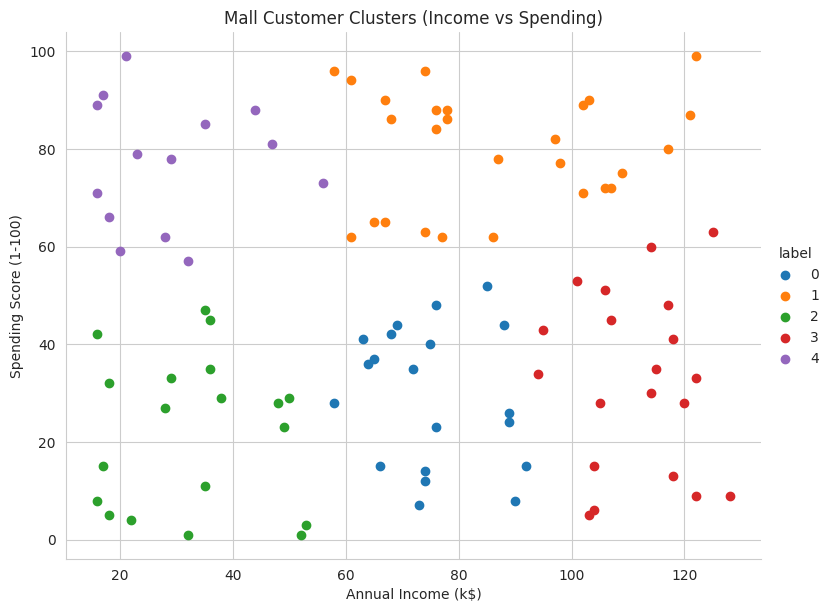

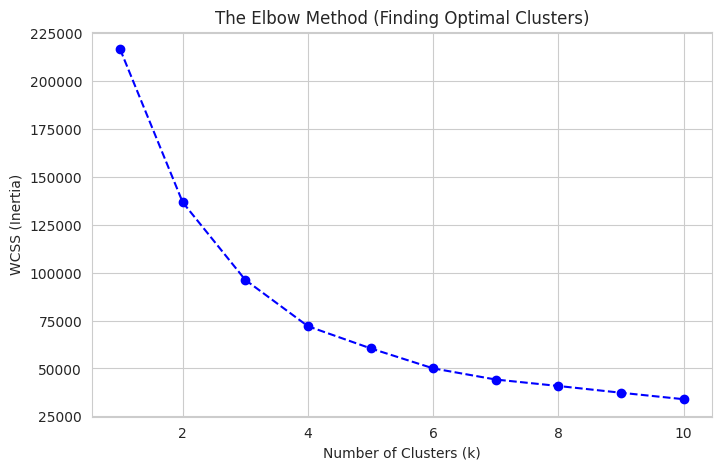

In [9]:
sns.set_style("whitegrid")
facet = sns.FacetGrid(Final, hue="label", height=6, aspect=1.3)
facet.map(plt.scatter, "Annual Income (k$)", "Spending Score (1-100)")
facet.add_legend()
plt.title("Mall Customer Clusters (Income vs Spending)")
plt.show()

features_el = df.iloc[:, [2, 3, 4]].values
wcss = []

for i in range(1, 11):
    elbow_model = KMeans(n_clusters=i, n_init=10, random_state=42)
    elbow_model.fit(features_el)
    wcss.append(elbow_model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--', color='b')
plt.title("The Elbow Method (Finding Optimal Clusters)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS (Inertia)")
plt.grid(True)
plt.show()
